## Tree-based models building (Daily)

Predicts daily `actual_consumption` 1-7 days ahead - direct multi-step: one model per horizon `h=1..7`, weather/price/lag features anchored to "today" for every h, but calendar features (deterministic - always knowable in advance) use the target day's values instead. Only the target itself shifts forward. 4 model types compared (XGBoost, CatBoost, LightGBM, RandomForest), best one picked per horizon.

**Steps:**

Model Building :

1. Load data, select features, build lags
2. Split train (2019-22) / val (2023) / test (2024)
3. Build the 7 shifted targets (`h=1`=today ... `h=7`=6 days ahead); each horizon's `X` swaps in that horizon's target-day calendar values in place of today's
4. CV-tune each model type per horizon → pick the best per horizon → refit on train+val → evaluate on test
5. Export 2024 predictions to CSV

Model Analysis : \
6. error patterns, feature importance, SHAP

See "Future Work" at the end for ideas not yet implemented.

In [1]:
import pandas as pd 
import numpy as np 

# plot
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt
import seaborn as sns

# CV 
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# tree models 
from catboost import CatBoostRegressor
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor

# Model Evaluation 
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
data_daily = pd.read_csv("../../../data/final/data_daily.csv")
data_daily.head(5)

,Unnamed: 0,date_from,date_to,date_from_utc,actual_consumption,actual_consumption_incl_pumped,hydro_pumped_storage,residual_load,month,day_of_week_raw,...,ipi_ei_yoy,ipi_ei_staleness_days,ipi_ei_ref_month,ipi_ei_release_date,ipi_ei_release_source,hdd,daylight_duration,shortwave_radiation_sum,wind_speed_10m_mean,precipitation_sum
0,0,2019-01-01,2019-01-02,2018-12-31 23:00:00,1097118.75,1150739.75,53621.00,277981.25,1,1,...,-3.5681,62,2018-10,2018-12-10,rule,12.068589,28528.015333,1.489070,24.580942,1.873295
1,1,2019-01-02,2019-01-03,2019-01-01 23:00:00,1388494.25,1424715.50,36221.25,669048.50,1,2,...,-3.5681,63,2018-10,2018-12-10,rule,15.871967,28599.042529,3.109106,20.987059,0.963644
2,2,2019-01-03,2019-01-04,2019-01-02 23:00:00,1466308.25,1490488.00,24179.75,1150431.75,1,3,...,-3.5681,64,2018-10,2018-12-10,rule,18.296275,28676.581542,2.574303,11.550165,1.044604
3,3,2019-01-04,2019-01-05,2019-01-03 23:00:00,1486876.25,1512694.00,25817.75,948617.25,1,4,...,-3.5681,65,2018-10,2018-12-10,rule,16.385933,28760.423758,0.914211,15.252564,1.011612
4,4,2019-01-05,2019-01-06,2019-01-04 23:00:00,1315755.00,1363757.75,48002.75,700158.25,1,5,...,-3.5681,66,2018-10,2018-12-10,rule,13.022892,28850.352023,1.098681,19.261519,5.634677


In [3]:
data_daily.date_from

0       2019-01-01
1       2019-01-02
2       2019-01-03
3       2019-01-04
4       2019-01-05
           ...    
2187    2024-12-27
2188    2024-12-28
2189    2024-12-29
2190    2024-12-30
2191    2024-12-31
Name: date_from, Length: 2192, dtype: str

### Column Selection

- Generations: removed
- Sunlight: removed `daylight_duration` (highly correlated with other sunlight features)
- Prices: removed `gas_price_eu_usd` (highly correlated with `day_ahead_price_mean`, less explainable)

In [4]:
y = ['actual_consumption']

time_date = ['date_from', 'month', 'day_of_week_raw', 'is_holiday',
            'is_weekday', 'weighted_regional_holiday', 'weighted_school_holiday', 
            'is_bridge_day', 'is_christmas_new_year', 'is_dst', 'is_dst_transition_day']


# generations = ['generation_wind_onshore', 'generation_wind_offshore',
#     'generation_solar', 'generation_lignite', 'generation_hard_coal',
#     'generation_natural_gas', 'generation_nuclear']



prices = ['day_ahead_price_mean'] 

# past 7 days' average price (excludes today itself, so it's a separate "recent price
# environment" signal rather than just smoothing today's own value)
data_daily['day_ahead_price_mean_7d'] = (
    data_daily['day_ahead_price_mean'].shift(1).rolling(7).mean()
)
prices = prices + ['day_ahead_price_mean_7d']

weather_columns = [
    'hdd', 'shortwave_radiation_sum', 
    'wind_speed_10m_mean', 'precipitation_sum'
]  



fourier_columns = [
    'sin_y1', 'cos_y1', 'sin_y2', 'cos_y2', 'sin_y3',
    'cos_y3' ]

others = ['oxcgrt_stringency', 'ipi_ei_level', 'industrial_confidence', 
          'solar_capacity_mw']

### Add solar_capacity_mw * shortwave_radiation_sum

In [5]:
data_daily["solar_radiation_combi"] = data_daily["solar_capacity_mw"] * data_daily["shortwave_radiation_sum"]

if "solar_radiation_combi" not in others : 
    others = others + ["solar_radiation_combi"]

others.remove("solar_capacity_mw")
weather_columns.remove("shortwave_radiation_sum")


In [6]:
data_daily.columns

Index(['Unnamed: 0', 'date_from', 'date_to', 'date_from_utc',
       'actual_consumption', 'actual_consumption_incl_pumped',
       'hydro_pumped_storage', 'residual_load', 'month', 'day_of_week_raw',
       'day_of_week', 'is_holiday', 'is_weekday', 'weighted_regional_holiday',
       'weighted_school_holiday', 'is_bridge_day', 'is_christmas_new_year',
       'is_dst', 'is_dst_transition_day', 'gas_price_eu_usd',
       'industrial_confidence', 'day_ahead_price_mean', 'day_ahead_price_min',
       'day_ahead_price_max', 'sin_y1', 'cos_y1', 'sin_y2', 'cos_y2', 'sin_y3',
       'cos_y3', 'sin_y4', 'cos_y4', 'sin_y5', 'cos_y5', 'sin_y6', 'cos_y6',
       'sin_y7', 'cos_y7', 'sin_y8', 'cos_y8', 'sin_y9', 'cos_y9', 'sin_y10',
       'cos_y10', 'generation_wind_onshore', 'generation_wind_offshore',
       'generation_solar', 'generation_lignite', 'generation_hard_coal',
       'generation_natural_gas', 'generation_nuclear', 'solar_capacity_mw',
       'oxcgrt_stringency', 'oxcgrt_c1_school'

### Lag Selection

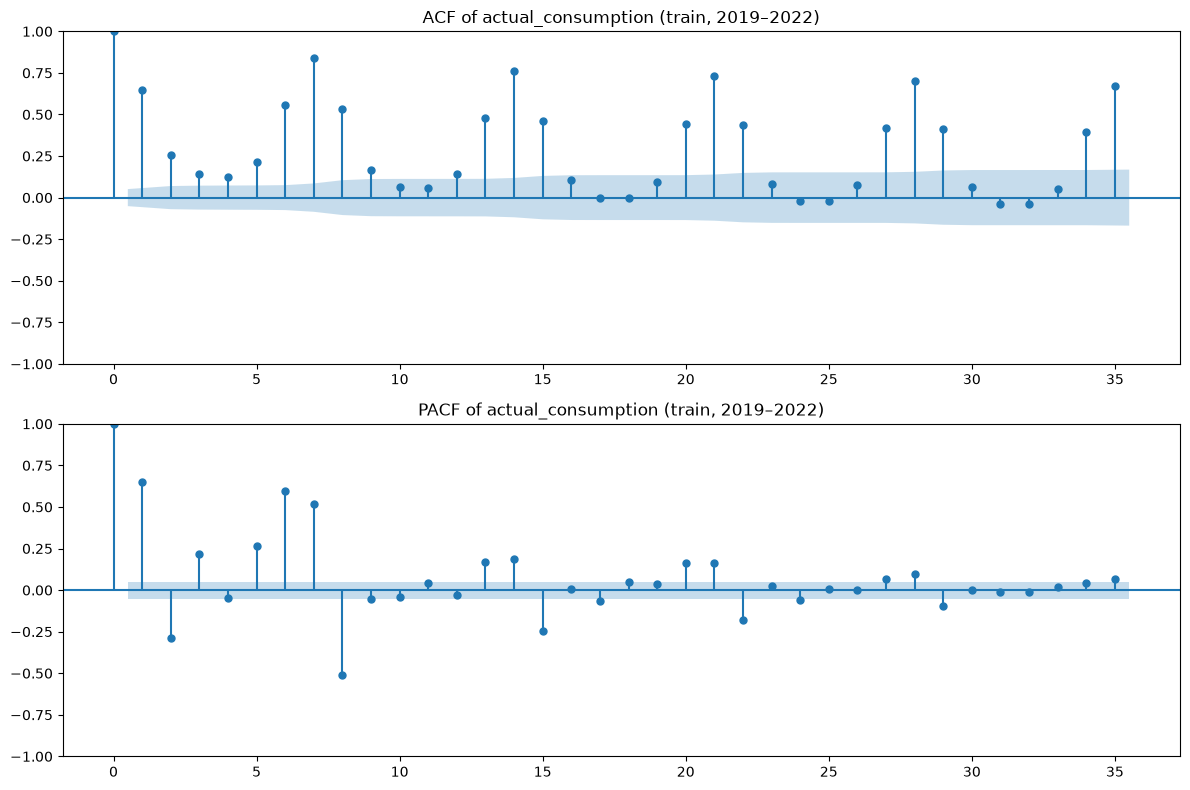

In [7]:
### add time / other features 
### ACF, PACF 

subset = data_daily.query("date_from >= '2019-01-01' and date_from <= '2022-12-31'")


n_lags = 35  # ~5 weeks, enough to see a couple of weekly cycles decay

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(subset.actual_consumption, lags=n_lags, ax=axes[0])
axes[0].set_title("ACF of actual_consumption (train, 2019–2022)")

plot_pacf(subset.actual_consumption, lags=n_lags, method="ywm", ax=axes[1])
axes[1].set_title("PACF of actual_consumption (train, 2019–2022)")

plt.tight_layout()
plt.show()

In [8]:
### Add lags into datasets  

for lag in [1, 2, 7]:
    data_daily[f"lag_{lag}"] = data_daily["actual_consumption"].shift(lag)

lag_cols = ["lag_1", "lag_2", "lag_7"]

time_date.extend(lag_cols)

In [9]:
data_daily = data_daily.loc[:,y+time_date+prices+weather_columns
                +fourier_columns+others]

data_daily.head()

,actual_consumption,date_from,month,day_of_week_raw,is_holiday,is_weekday,weighted_regional_holiday,weighted_school_holiday,is_bridge_day,is_christmas_new_year,...,sin_y1,cos_y1,sin_y2,cos_y2,sin_y3,cos_y3,oxcgrt_stringency,ipi_ei_level,industrial_confidence,solar_radiation_combi
0,1097118.75,2019-01-01,1,1,True,True,0.0,0.448877,False,True,...,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.0,100.0,3.8,67702.015735
1,1388494.25,2019-01-02,1,2,False,True,0.0,0.448877,False,False,...,0.017202,0.999852,0.034398,0.999408,0.051584,0.998669,0.0,100.0,3.8,141475.202849
2,1466308.25,2019-01-03,1,3,False,True,0.0,0.448877,False,False,...,0.034398,0.999408,0.068755,0.997634,0.103031,0.994678,0.0,100.0,3.8,117171.043533
3,1486876.25,2019-01-04,1,4,False,True,0.0,0.448877,False,False,...,0.051584,0.998669,0.103031,0.994678,0.154204,0.988039,0.0,100.0,3.8,41617.902422
4,1315755.00,2019-01-05,1,5,False,False,0.0,0.075100,False,False,...,0.068755,0.997634,0.137185,0.990545,0.204966,0.978769,0.0,100.0,3.8,50015.974576


In [10]:
# Training set, Validation set, Testing set 

data_daily['date_from'] = pd.to_datetime(data_daily['date_from'])
data_daily = data_daily.sort_values('date_from').reset_index(drop=True)

train_mask = data_daily['date_from'].dt.year <= 2022
val_mask   = data_daily['date_from'].dt.year == 2023
test_mask  = data_daily['date_from'].dt.year == 2024

feature_cols = [c for c in data_daily.columns if c not in ['actual_consumption', 'date_from']]

X_train, y_train = data_daily.loc[train_mask, feature_cols], data_daily.loc[train_mask, 'actual_consumption']
X_val,   y_val   = data_daily.loc[val_mask, feature_cols],   data_daily.loc[val_mask, 'actual_consumption']
X_test,  y_test  = data_daily.loc[test_mask, feature_cols],  data_daily.loc[test_mask, 'actual_consumption']

print(f"train: {X_train.shape}, {y_train.index.min()}..{y_train.index.max()}")
print(f"val:   {X_val.shape}, {data_daily.loc[val_mask, 'date_from'].min().date()}..{data_daily.loc[val_mask, 'date_from'].max().date()}")
print(f"test:  {X_test.shape}, {data_daily.loc[test_mask, 'date_from'].min().date()}..{data_daily.loc[test_mask, 'date_from'].max().date()}")

train: (1461, 28), 0..1460
val:   (365, 28), 2023-01-01..2023-12-31
test:  (366, 28), 2024-01-01..2024-12-31


In [31]:
X_train.head()

,month,day_of_week_raw,is_holiday,is_weekday,weighted_regional_holiday,weighted_school_holiday,is_bridge_day,is_christmas_new_year,is_dst,is_dst_transition_day,...,sin_y1,cos_y1,sin_y2,cos_y2,sin_y3,cos_y3,oxcgrt_stringency,ipi_ei_level,industrial_confidence,solar_radiation_combi
0,1,1,True,True,0.0,0.448877,False,True,False,False,...,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.0,100.0,3.8,67702.015735
1,1,2,False,True,0.0,0.448877,False,False,False,False,...,0.017202,0.999852,0.034398,0.999408,0.051584,0.998669,0.0,100.0,3.8,141475.202849
2,1,3,False,True,0.0,0.448877,False,False,False,False,...,0.034398,0.999408,0.068755,0.997634,0.103031,0.994678,0.0,100.0,3.8,117171.043533
3,1,4,False,True,0.0,0.448877,False,False,False,False,...,0.051584,0.998669,0.103031,0.994678,0.154204,0.988039,0.0,100.0,3.8,41617.902422
4,1,5,False,False,0.0,0.075100,False,False,False,False,...,0.068755,0.997634,0.137185,0.990545,0.204966,0.978769,0.0,100.0,3.8,50015.974576


In [32]:
X_train.columns

Index(['month', 'day_of_week_raw', 'is_holiday', 'is_weekday',
       'weighted_regional_holiday', 'weighted_school_holiday', 'is_bridge_day',
       'is_christmas_new_year', 'is_dst', 'is_dst_transition_day', 'lag_1',
       'lag_2', 'lag_7', 'day_ahead_price_mean', 'day_ahead_price_mean_7d',
       'hdd', 'wind_speed_10m_mean', 'precipitation_sum', 'sin_y1', 'cos_y1',
       'sin_y2', 'cos_y2', 'sin_y3', 'cos_y3', 'oxcgrt_stringency',
       'ipi_ei_level', 'industrial_confidence', 'solar_radiation_combi'],
      dtype='str')

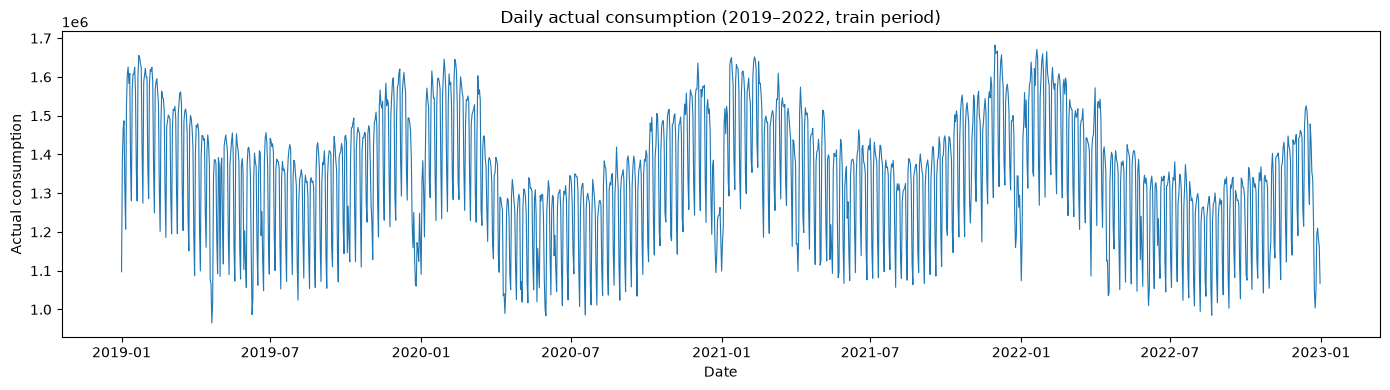

In [11]:
### Time-series model 

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))
plt.plot(
    data_daily.loc[train_mask, 'date_from'],
    data_daily.loc[train_mask, 'actual_consumption'],
    linewidth=0.8,
)
plt.xlabel("Date")
plt.ylabel("Actual consumption")
plt.title("Daily actual consumption (2019–2022, train period)")
plt.tight_layout()
plt.show()

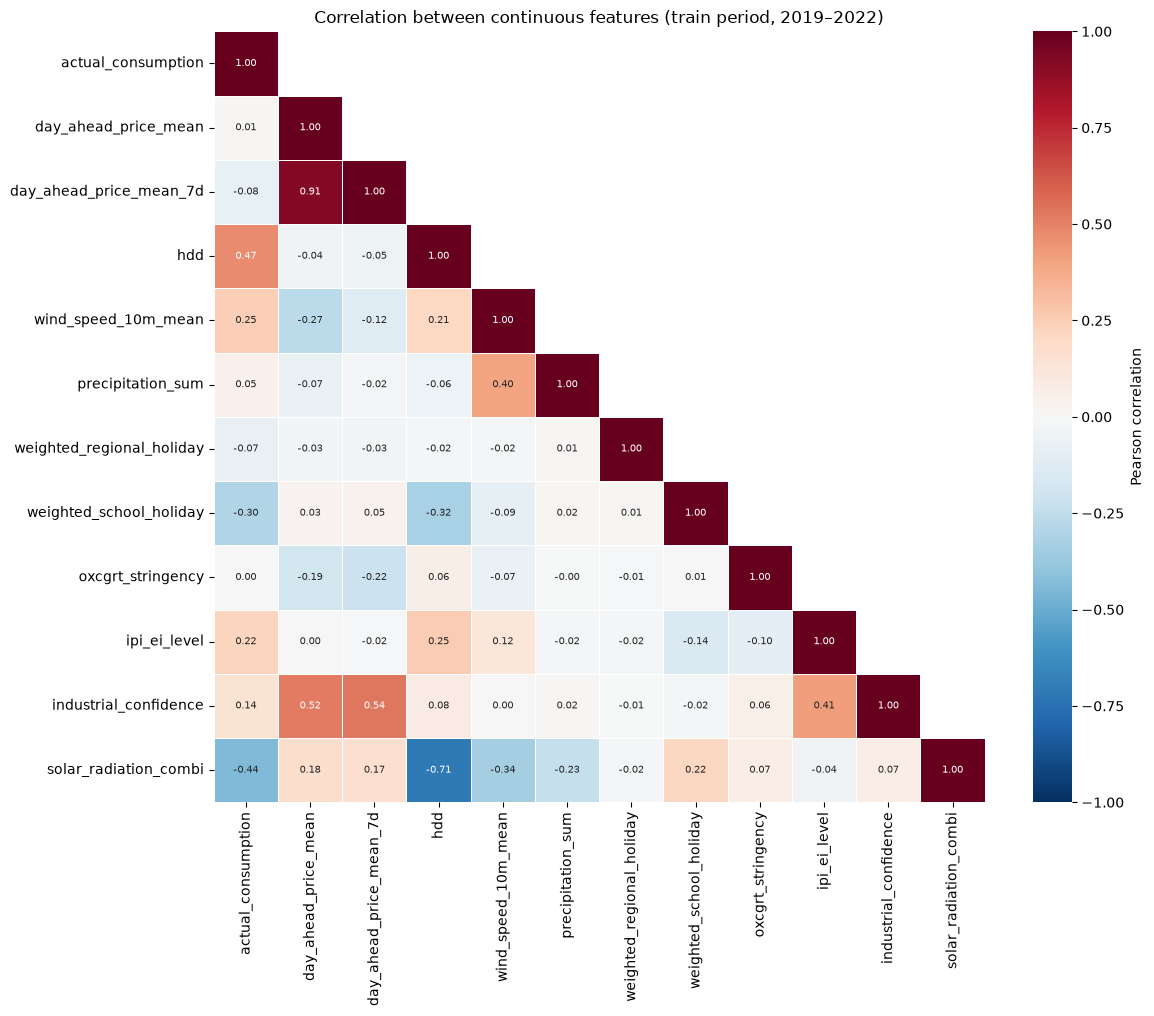

In [12]:
# only the continuous columns - drop booleans (is_holiday, ...), ordinal/categorical
# (month, day_of_week_raw), date_from, and the 20 fourier sin/cos terms (deterministic
# calendar encodings, not informative here and would clutter the matrix)
continuous_cols = (
    prices + weather_columns
    + ['weighted_regional_holiday', 'weighted_school_holiday'] 
    + others
)

# computed on the train period only, so the plot isn't informed by val/test
corr = data_daily.loc[train_mask, ['actual_consumption'] + continuous_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    corr, mask=mask, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
    annot=True, fmt='.2f', annot_kws={'size': 7},
    square=True, linewidths=0.5, cbar_kws={'label': 'Pearson correlation'}, ax=ax
)
ax.set_title('Correlation between continuous features (train period, 2019–2022)')
plt.tight_layout()
plt.show()

## Model Building

Target prep, per-model CV tuning, final model selection, export.

### Multi-step Target Preparation

Direct forecasting: `h=1`=today (nowcast), ..., `h=7`=6 days ahead. Weather/price/lags (`lag_1/2/7`) stay anchored to today for every h - those aren't knowable for the target day. Calendar features (`month`, `day_of_week_raw`, `is_holiday`, `is_weekday`, `weighted_regional_holiday`, `weighted_school_holiday`, `is_bridge_day`, `is_christmas_new_year`, `is_dst`, `is_dst_transition_day`, yearly fourier terms) are deterministic, so instead each horizon uses the *target day's* values of these in place of today's (same `shift(-(h-1))` used to build the target itself, so both share the same tail-NaN rows). Tail rows with no future answer yet are dropped per horizon.

In [13]:
# Build the shifted targets - h=1 is "today" (no shift), h=2..8 are 1..7 days ahead

max_horizon = 7

targets = {}
for h in range(1, max_horizon + 1):
    targets[h] = data_daily['actual_consumption'].shift(-(h - 1))

targets[1].equals(data_daily['actual_consumption'])  # sanity check: h=1 should be identical to the un-shifted series

True

In [14]:
# Split each horizon's target with the same train/val/test masks as the single-day model,
# dropping rows where the shifted target is NaN (tail of the whole series)
#
# Calendar features are deterministic, so X uses the TARGET day's calendar values
# instead of today's - replaces them (same column names/count), rather than adding a
# separate set. Weather/price/lags stay anchored to today - those aren't knowable yet
# for the target day.

calendar_cols = [
    'month', 'day_of_week_raw', 'is_holiday', 'is_weekday',
    'weighted_regional_holiday', 'weighted_school_holiday',
    'is_bridge_day', 'is_christmas_new_year', 'is_dst', 'is_dst_transition_day',
] + fourier_columns

# shift() upcasts bool/int columns to object/float wherever it introduces NaN at the
# tail - restore the original dtypes after slicing out those NaN rows (where the dtype
# cast is safe again), otherwise XGBoost rejects the "object" dtype outright
calendar_dtypes = data_daily[calendar_cols].dtypes.to_dict()

X_train_h, X_val_h, X_test_h = {}, {}, {}
y_train_h, y_val_h, y_test_h = {}, {}, {}

for h in range(1, max_horizon + 1):
    valid = targets[h].notna()

    y_train_h[h] = targets[h][train_mask & valid]
    y_val_h[h]   = targets[h][val_mask & valid]
    y_test_h[h]  = targets[h][test_mask & valid]

    target_calendar = data_daily[calendar_cols].shift(-(h - 1))

    X_train_h[h] = X_train.drop(columns=calendar_cols).loc[y_train_h[h].index].join(
        target_calendar.loc[y_train_h[h].index].astype(calendar_dtypes))
    X_val_h[h]   = X_val.drop(columns=calendar_cols).loc[y_val_h[h].index].join(
        target_calendar.loc[y_val_h[h].index].astype(calendar_dtypes))
    X_test_h[h]  = X_test.drop(columns=calendar_cols).loc[y_test_h[h].index].join(
        target_calendar.loc[y_test_h[h].index].astype(calendar_dtypes))

for h in range(1, max_horizon + 1):
    print(f"h={h}: train={X_train_h[h].shape}, val={X_val_h[h].shape}, test={X_test_h[h].shape}")

h=1: train=(1461, 28), val=(365, 28), test=(366, 28)
h=2: train=(1461, 28), val=(365, 28), test=(365, 28)
h=3: train=(1461, 28), val=(365, 28), test=(364, 28)
h=4: train=(1461, 28), val=(365, 28), test=(363, 28)
h=5: train=(1461, 28), val=(365, 28), test=(362, 28)
h=6: train=(1461, 28), val=(365, 28), test=(361, 28)
h=7: train=(1461, 28), val=(365, 28), test=(360, 28)


In [15]:
X_train_h[2].columns

Index(['lag_1', 'lag_2', 'lag_7', 'day_ahead_price_mean',
       'day_ahead_price_mean_7d', 'hdd', 'wind_speed_10m_mean',
       'precipitation_sum', 'oxcgrt_stringency', 'ipi_ei_level',
       'industrial_confidence', 'solar_radiation_combi', 'month',
       'day_of_week_raw', 'is_holiday', 'is_weekday',
       'weighted_regional_holiday', 'weighted_school_holiday', 'is_bridge_day',
       'is_christmas_new_year', 'is_dst', 'is_dst_transition_day', 'sin_y1',
       'cos_y1', 'sin_y2', 'cos_y2', 'sin_y3', 'cos_y3'],
      dtype='str')

In [16]:
# Evaluation function

results = []

def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mape = (abs((y_true - y_pred) / y_true)).mean() * 100
    print(f"{name:25s} MAE={mae:>12,.0f}  RMSE={rmse:>12,.0f}  MAPE={mape:5.2f}%")
    results.append({"model": name, "MAE": mae, "RMSE": rmse, "MAPE": mape})

### Multi-step XGBoost - CV tuning (per horizon)

`GridSearchCV` + `TimeSeriesSplit` per horizon (h=1..7), on that horizon's own train set.

In [ ]:
# edit this to change what gets searched
param_grid = {
    "max_depth": [3, 5, 7],
    "n_estimators": [200, 500, 800],
    "learning_rate": [0.01, 0.05, 0.1],
    "min_child_weight": [1, 5, 10],
}

tscv = TimeSeriesSplit(n_splits=5)

xgb_models_h = {}
best_params_h = {}

for h in range(1, max_horizon + 1):
    search = GridSearchCV(
        estimator=xgb.XGBRegressor(random_state=42, n_jobs=1),
        param_grid=param_grid,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )
    search.fit(X_train_h[h], y_train_h[h])

    xgb_models_h[h] = search.best_estimator_
    best_params_h[h] = search.best_params_

    print(f"h={h}  best_params={search.best_params_}")

In [ ]:
# Per-horizon evaluation - each horizon prints/records its own MAE, RMSE, MAPE (val + test)

for h in range(1, max_horizon + 1):
    model = xgb_models_h[h]
    evaluate(y_val_h[h], model.predict(X_val_h[h]), f"XGBoost h={h} - val")


### Multi-step CatBoost - CV tuning + evaluation

Same as XGBoost, with `depth`/`iterations`/`l2_leaf_reg` in place of `max_depth`/`n_estimators`/`min_child_weight`.

In [ ]:
# edit this to change what gets searched
param_grid_cb = {
    "depth": [3, 5, 7],
    "iterations": [200, 500, 800],
    "learning_rate": [0.01, 0.05, 0.1],
    "l2_leaf_reg": [1, 5, 10],
}

cb_models_h = {}
best_params_cb_h = {}

for h in range(1, max_horizon + 1):
    search = GridSearchCV(
        estimator=CatBoostRegressor(random_state=42, verbose=False, thread_count=1),
        param_grid=param_grid_cb,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )
    search.fit(X_train_h[h], y_train_h[h])

    cb_models_h[h] = search.best_estimator_
    best_params_cb_h[h] = search.best_params_

    print(f"h={h}  best_params={search.best_params_}")

In [ ]:
# Per-horizon evaluation - each horizon prints/records its own MAE, RMSE, MAPE (val + test)

for h in range(1, max_horizon + 1):
    model = cb_models_h[h]
    evaluate(y_val_h[h], model.predict(X_val_h[h]), f"CatBoost h={h} - val")

### Multi-step LightGBM - CV tuning + evaluation

Same structure; `num_leaves` is the main complexity control instead of `max_depth`.

In [ ]:
# edit this to change what gets searched
param_grid_lgb = {
    "num_leaves": [15, 31, 63],
    "n_estimators": [200, 500, 800],
    "learning_rate": [0.01, 0.05, 0.1],
    "min_child_samples": [10, 20, 40],
}

lgb_models_h = {}
best_params_lgb_h = {}

for h in range(1, max_horizon + 1):
    search = GridSearchCV(
        estimator=lgb.LGBMRegressor(random_state=42, n_jobs=1, verbose=-1),
        param_grid=param_grid_lgb,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )
    search.fit(X_train_h[h], y_train_h[h])

    lgb_models_h[h] = search.best_estimator_
    best_params_lgb_h[h] = search.best_params_

    print(f"h={h}  best_params={search.best_params_}")

In [ ]:
# Per-horizon evaluation - each horizon prints/records its own MAE, RMSE, MAPE (val + test)

for h in range(1, max_horizon + 1):
    model = lgb_models_h[h]
    evaluate(y_val_h[h], model.predict(X_val_h[h]), f"LightGBM h={h} - val")

### Multi-step RandomForest - CV tuning + evaluation

Same structure; no `learning_rate` (bagging, not boosting), and `.dropna()` per horizon (RandomForest doesn't support NaN).

In [ ]:
# edit this to change what gets searched
param_grid_rf = {
    "max_depth": [5, 10, 20],
    "n_estimators": [200, 500, 800],
    "min_samples_leaf": [1, 5, 10],
}

rf_models_h = {}
best_params_rf_h = {}

for h in range(1, max_horizon + 1):
    X_train_rf_h = X_train_h[h].dropna()
    y_train_rf_h = y_train_h[h].loc[X_train_rf_h.index]

    search = GridSearchCV(
        estimator=RandomForestRegressor(random_state=42, n_jobs=1),
        param_grid=param_grid_rf,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )
    search.fit(X_train_rf_h, y_train_rf_h)

    rf_models_h[h] = search.best_estimator_
    best_params_rf_h[h] = search.best_params_

    print(f"h={h}  best_params={search.best_params_}")

In [ ]:
# Per-horizon evaluation - each horizon prints/records its own MAE, RMSE, MAPE (val + test)

for h in range(1, max_horizon + 1):
    model = rf_models_h[h]
    evaluate(y_val_h[h], model.predict(X_val_h[h]), f"RandomForest h={h} - val")

### Final per-horizon models

Best model + CV params per h, refit on 2019-2023, evaluated once on 2024. Each horizon is refit 5 times with different random seeds; the test MAE/RMSE/MAPE are averaged across seeds for `summary_final`, and `final_models_h[h]` keeps whichever seed scored the lowest test MAE. `best_model_config` (hand-picked below, from the CV results above) is also saved to `src/results/tree-based/best_model_config_daily.json` right after it's defined - `run_tree_based.py` reads that file instead of hand-copying this dict, so there's one place for this choice, not two that can drift apart:

| h | model | params |
|---|---|---|
| 1 | LightGBM | `learning_rate=0.01, min_child_samples=10, n_estimators=500, num_leaves=15` |
| 2 | XGBoost | `learning_rate=0.01, max_depth=5, min_child_weight=10, n_estimators=800` |
| 3 | CatBoost | `depth=3, iterations=500, l2_leaf_reg=10, learning_rate=0.05` |
| 4 | RandomForest | `max_depth=10, min_samples_leaf=5, n_estimators=800` |
| 5 | LightGBM | `learning_rate=0.01, min_child_samples=20, n_estimators=500, num_leaves=31` |
| 6 | LightGBM | `learning_rate=0.01, min_child_samples=10, n_estimators=500, num_leaves=15` |
| 7 | RandomForest | `max_depth=5, min_samples_leaf=5, n_estimators=800` |

RandomForest horizons (h=4,7) get `.dropna()` on train+val first.

In [17]:
# edit this to change which model/params each horizon uses
best_model_config = {
    1: ("LightGBM", lgb.LGBMRegressor, dict(
        learning_rate=0.01, min_child_samples=10, n_estimators=500, num_leaves=15,
        random_state=42, n_jobs=-1, verbose=-1,
    )),
    2: ("XGBoost", xgb.XGBRegressor, dict(
        learning_rate=0.01, max_depth=5, min_child_weight=10, n_estimators=800,
        random_state=42, n_jobs=-1,
    )),
    3: ("CatBoost", CatBoostRegressor, dict(
        depth=3, iterations=500, l2_leaf_reg=10, learning_rate=0.05,
        random_state=42, verbose=False,
    )),
    4: ("RandomForest", RandomForestRegressor, dict(
        max_depth=10, min_samples_leaf=5, n_estimators=800,
        random_state=42, n_jobs=-1,
    )),
    5: ("LightGBM", lgb.LGBMRegressor, dict(
        learning_rate=0.01, min_child_samples=20, n_estimators=500, num_leaves=31,
        random_state=42, n_jobs=-1, verbose=-1,
    )),
    6: ("LightGBM", lgb.LGBMRegressor, dict(
        learning_rate=0.01, min_child_samples=10, n_estimators=500, num_leaves=15,
        random_state=42, n_jobs=-1, verbose=-1,
    )),
    7: ("RandomForest", RandomForestRegressor, dict(
        max_depth=5, min_samples_leaf=5, n_estimators=800,
        random_state=42, n_jobs=-1,
    )),
}

In [18]:
# persist the hand-picked config as JSON, instead of hand-copying this dict into
# run_tree_based.py too - that script now reads this file, so there's only one place
# where the model/params choice lives and the two can't drift apart

import json
from pathlib import Path

config_path = Path("../../../results/tree-based/best_model_config_daily.json")
config_path.parent.mkdir(parents=True, exist_ok=True)
with open(config_path, "w") as f:
    json.dump(
        {h: {"model": name, "params": params} for h, (name, _, params) in best_model_config.items()},
        f, indent=2,
    )
print(f"saved best_model_config to {config_path.resolve()}")

saved best_model_config to /Users/borya/Documents/Mannheim Documents/First Semester/AI Deployment and Operation/AI-Deployment(New)/src/results/tree-based/best_model_config_daily.json


In [19]:
# Refit each horizon 5 times with different random seeds, average the test MAE/RMSE/MAPE
# across seeds into one "Final h={h}" entry (more robust than resting on a single seed's
# luck). final_models_h[h] keeps whichever seed had the lowest test MAE - used by
# everything below (export, save, SHAP, patch experiment) - summary_final's numbers are
# still the 5-seed average, not this best seed's own numbers.

seeds = [42, 43, 44, 45, 46]

final_models_h = {}

for h in range(1, max_horizon + 1):
    name, model_cls, params = best_model_config[h]

    X_trainval = pd.concat([X_train_h[h], X_val_h[h]])
    y_trainval = pd.concat([y_train_h[h], y_val_h[h]])

    if name == "RandomForest":  # doesn't support NaN
        X_trainval = X_trainval.dropna()
        y_trainval = y_trainval.loc[X_trainval.index]

    seed_metrics = []
    best_mae = np.inf

    for seed in seeds:
        model = model_cls(**{**params, "random_state": seed})
        model.fit(X_trainval, y_trainval)
        y_pred = model.predict(X_test_h[h])

        mae = mean_absolute_error(y_test_h[h], y_pred)
        seed_metrics.append({
            "MAE": mae,
            "RMSE": mean_squared_error(y_test_h[h], y_pred) ** 0.5,
            "MAPE": (abs((y_test_h[h] - y_pred) / y_test_h[h])).mean() * 100,
        })

        if mae < best_mae:
            best_mae = mae
            final_models_h[h] = model

    avg_mae = np.mean([m["MAE"] for m in seed_metrics])
    avg_rmse = np.mean([m["RMSE"] for m in seed_metrics])
    avg_mape = np.mean([m["MAPE"] for m in seed_metrics])

    model_name = f"Final h={h} ({name}) - test"
    print(f"{model_name:25s} MAE={avg_mae:>12,.0f}  RMSE={avg_rmse:>12,.0f}  MAPE={avg_mape:5.2f}%  "
          f"(avg of {len(seeds)} seeds, best seed MAE={best_mae:,.0f})")
    results.append({"model": model_name, "MAE": avg_mae, "RMSE": avg_rmse, "MAPE": avg_mape})

Final h=1 (LightGBM) - test MAE=      25,212  RMSE=      34,207  MAPE= 2.02%  (avg of 5 seeds, best seed MAE=25,212)
Final h=2 (XGBoost) - test MAE=      27,924  RMSE=      36,241  MAPE= 2.21%  (avg of 5 seeds, best seed MAE=27,924)
Final h=3 (CatBoost) - test MAE=      30,220  RMSE=      38,746  MAPE= 2.39%  (avg of 5 seeds, best seed MAE=29,088)
Final h=4 (RandomForest) - test MAE=      37,062  RMSE=      48,744  MAPE= 2.92%  (avg of 5 seeds, best seed MAE=36,844)
Final h=5 (LightGBM) - test MAE=      32,262  RMSE=      41,696  MAPE= 2.54%  (avg of 5 seeds, best seed MAE=32,262)
Final h=6 (LightGBM) - test MAE=      33,610  RMSE=      44,434  MAPE= 2.67%  (avg of 5 seeds, best seed MAE=33,610)
Final h=7 (RandomForest) - test MAE=      40,701  RMSE=      55,953  MAPE= 3.26%  (avg of 5 seeds, best seed MAE=40,543)


In [20]:
summary_final = pd.DataFrame([r for r in results if r["model"].startswith("Final h=")])
summary_final = summary_final.set_index("model")[["MAE", "RMSE", "MAPE"]]
summary_final

,MAE,RMSE,MAPE
model,,,
Final h=1 (LightGBM) - test,25211.681496,34206.960863,2.015827
Final h=2 (XGBoost) - test,27924.151370,36241.119946,2.213226
Final h=3 (CatBoost) - test,30219.657943,38746.235491,2.386678
Final h=4 (RandomForest) - test,37061.540458,48743.911898,2.920325
Final h=5 (LightGBM) - test,32262.450627,41695.996103,2.538051
Final h=6 (LightGBM) - test,33610.404381,44433.787280,2.670363
Final h=7 (RandomForest) - test,40701.466277,55953.301207,3.255613


In [21]:
# Save summary_final as a markdown table - a static "final results so far" snapshot,
# so the numbers can be checked without opening/re-running the notebook. Written by hand
# instead of DataFrame.to_markdown() (needs the `tabulate` package, not a project dependency).

from pathlib import Path

summary_lines = [
    "| model | MAE | RMSE | MAPE |",
    "|---|---|---|---|",
]
for model_name, row in summary_final.iterrows():
    summary_lines.append(f"| {model_name} | {row['MAE']:,.0f} | {row['RMSE']:,.0f} | {row['MAPE']:.2f}% |")

summary_path = Path("../../../results/tree-based/Model-comparison-result/daily/summary_final.md")
summary_path.parent.mkdir(parents=True, exist_ok=True)
summary_path.write_text("\n".join(summary_lines))
print(f"saved summary to {summary_path.resolve()}")

saved summary to /Users/borya/Documents/Mannheim Documents/First Semester/AI Deployment and Operation/AI-Deployment(New)/src/results/tree-based/Model-comparison-result/daily/summary_final.md


### 2024 predictions (long format, in-notebook check only)

One row per (origin_date, step): `target_time = origin_date + (step-1)` days, `y_true`/`y_pred` from `y_test_h[step]`/`final_models_h[step]`. All 7 horizons stacked; rows thin out near year-end for larger steps (tail-NaN drop). Not written to disk here - `run_tree_based.py` is the only writer of the shared-format CSVs (`results/tree-based/forecasts/tree_daily_1d_test.csv`, `tree_daily_7d_test.csv`), so there's one place producing those files, not two with different schemas that can clobber each other.

In [22]:
rows = []

for h in range(1, max_horizon + 1):
    origin_date = data_daily.loc[X_test_h[h].index, "date_from"]
    target_time = origin_date + pd.Timedelta(days=h - 1)
    y_pred = final_models_h[h].predict(X_test_h[h])

    rows.append(pd.DataFrame({
        "origin_date": origin_date.values,
        "target_time": target_time.values,
        "step": h,
        "y_true": y_test_h[h].values,
        "y_pred": y_pred,
    }))

predictions_2024 = pd.concat(rows, ignore_index=True).sort_values(["origin_date", "step"]).reset_index(drop=True)
predictions_2024

,origin_date,target_time,step,y_true,y_pred
0,2024-01-01,2024-01-01,1,1021080.00,1.158217e+06
1,2024-01-01,2024-01-02,2,1271127.25,1.259321e+06
2,2024-01-01,2024-01-03,3,1354050.50,1.328891e+06
3,2024-01-01,2024-01-04,4,1381903.50,1.327578e+06
4,2024-01-01,2024-01-05,5,1366758.25,1.346110e+06
...,...,...,...,...,...
2536,2024-12-29,2024-12-30,2,1278285.00,1.238371e+06
2537,2024-12-29,2024-12-31,3,1204279.50,1.196820e+06
2538,2024-12-30,2024-12-30,1,1278285.00,1.261455e+06
2539,2024-12-30,2024-12-31,2,1204279.50,1.238572e+06


### Save final models

Persist `final_models_h[1..7]` via `joblib` for later inference - works uniformly regardless of each horizon's model type (LightGBM/XGBoost/CatBoost/RandomForest).

In [ ]:
import joblib
from pathlib import Path

model_dir = Path("../../../results/tree-based/models/daily")
model_dir.mkdir(parents=True, exist_ok=True)

for h in range(1, max_horizon + 1):
    joblib.dump(final_models_h[h], model_dir / f"final_model_h{h}.joblib")

print(f"saved {max_horizon} models to {model_dir.resolve()}")

## Model Result Analysis

h=1 actual vs predicted, worst-error days, SHAP (h=1 only). Figures saved to `results/tree-based/report/figures/daily/`.

### h=1 - 2024 actual vs predicted

`final_models_h[1]` predictions on `X_test_h[1]` vs true `y_test_h[1]`.

In [ ]:
from pathlib import Path

figures_dir = Path("../../../results/tree-based/report/figures/daily")
figures_dir.mkdir(parents=True, exist_ok=True)

dates_test_h1 = data_daily.loc[X_test_h[1].index, "date_from"]
y_pred_h1 = final_models_h[1].predict(X_test_h[1])
abs_error_h1 = np.abs(y_test_h[1].values - y_pred_h1)

top6_idx = np.argsort(abs_error_h1)[-6:]
top6_dates = dates_test_h1.values[top6_idx]

with plt.style.context("ggplot"):
    plt.figure(figsize=(14, 5))
    plt.plot(dates_test_h1, y_test_h[1].values, label="Actual", color="#4C72B0", linewidth=1.2)
    plt.plot(dates_test_h1, y_pred_h1, label=f"Predicted (h=1, {best_model_config[1][0]})",
             color="#C44E52", linewidth=1.2, alpha=0.8)
    plt.scatter(top6_dates, y_test_h[1].values[top6_idx],
                color="gold", edgecolor="black", s=80, zorder=5, label="Top 6 largest error")
    plt.xticks(top6_dates, [pd.Timestamp(d).strftime("%Y-%m-%d") for d in top6_dates],
               rotation=70, ha="right")
    plt.xlabel("Date")
    plt.ylabel("actual_consumption")
    plt.title("2024 (test) - Actual vs Predicted, h=1 (top 6 error days highlighted)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(figures_dir / "actual_vs_predicted_h1.png", dpi=150)
    plt.show()

In [25]:
errors_h1 = pd.DataFrame({
    "date": dates_test_h1.values,
    "actual": y_test_h[1].values,
    "predicted": y_pred_h1,
})
errors_h1["abs_error"] = (errors_h1["actual"] - errors_h1["predicted"]).abs()
errors_h1["pct_error"] = errors_h1["abs_error"] / errors_h1["actual"] * 100

errors_h1.sort_values("abs_error", ascending=False).head(10)

,date,actual,predicted,abs_error,pct_error
7,2024-01-08,1500717.75,1.362919e+06,137798.402867,9.182167
0,2024-01-01,1021080.00,1.158217e+06,137136.934826,13.430577
11,2024-01-12,1537871.75,1.419610e+06,118262.008120,7.689979
26,2024-01-27,1279784.75,1.395591e+06,115806.690409,9.048919
358,2024-12-24,1130943.25,1.235705e+06,104761.608096,9.263206
90,2024-03-31,864718.00,9.679382e+05,103220.180400,11.936860
121,2024-05-01,977648.50,1.080658e+06,103009.079166,10.536413
315,2024-11-11,1430760.00,1.334381e+06,96379.236545,6.736227
27,2024-01-28,1138178.50,1.229901e+06,91722.711843,8.058728
300,2024-10-27,1096052.00,1.008805e+06,87247.322796,7.960144


### Insights

Top 6 test-set (2024) error days for h=1, by mechanism:

- **Jan 1 (New Year's Day, Monday) - overestimated.** Even with `is_holiday=True`, SHAP shows `day_of_week_raw` alone still pushes the prediction up (the model learned Monday = demand surge), outweighing the holiday effect - actual demand came in much lower than predicted. `is_holiday × is_weekday` wouldn't fix this - it only flags "a weekday holiday", not *which* weekday. Needs `is_holiday × day_of_week_raw`.
- **Jan 8 and Jan 12 - underestimated.** Both are cold-spell days (`hdd`=19.1 and 22.4, roughly -1°C and -5°C); actual demand rose more than `hdd` alone predicted.
- **Jan 27 (Saturday) - overestimated.** Right after that cold spell ended; the lag features (`lag_1/2/7`) are still carrying the cold spell's demand level into the first warmer day.
- **Mar 31 (Easter Sunday) - overestimated.** Not flagged as `is_holiday` (falls on a Sunday), but demand is lower than an ordinary Sunday - `is_holiday` isn't precise enough, though this also confirms legal holidays do have lower demand than regular Sundays.
- **Dec 24 (Christmas Eve) - overestimated.** Legally a workday, but businesses close early / people take leave ahead of the long holiday - not captured by `is_christmas_new_year` or `is_bridge_day`.

### SHAP (h=1)

`shap.TreeExplainer`, computed on the h=1 validation set (`X_val_h[1]`).

In [ ]:
# SHAP, h=1 only - beeswarm shows both magnitude and direction, computed on the
# validation set (X_val_h[1])

import shap

shap_values_h = {}

h = 1

explainer = shap.TreeExplainer(final_models_h[h])
shap_values_h[h] = explainer(X_val_h[h])

shap.summary_plot(shap_values_h[h], X_val_h[h], show=False)
plt.title(f"SHAP summary - h={h} ({best_model_config[h][0]})")
plt.tight_layout()
plt.savefig(figures_dir / "shap_summary_h1.png", dpi=150)
plt.show()

### SHAP Value Analysis

Every continuous feature's value vs its own SHAP contribution, h=1 only, with a rolling-mean trend line. One figure per feature, saved to `results/tree-based/report/figures/daily/`.

In [ ]:
h = 1
# only the truly continuous physical quantities - not the booleans/ordinal calendar
# columns (is_*, month, day_of_week_raw) or the deterministic fourier terms
features_to_check = [
    "hdd", "wind_speed_10m_mean", "precipitation_sum",
    "day_ahead_price_mean", "day_ahead_price_mean_7d",
    "oxcgrt_stringency", "ipi_ei_level", "industrial_confidence", "solar_radiation_combi",
]

for feature in features_to_check:
    col_idx = list(X_val_h[h].columns).index(feature)
    vals = X_val_h[h][feature].values
    shap_vals = shap_values_h[h].values[:, col_idx]

    order = np.argsort(vals)
    vals_sorted = vals[order]
    shap_sorted = shap_vals[order]
    trend = pd.Series(shap_sorted).rolling(20, center=True, min_periods=1).mean()

    plt.figure(figsize=(8, 4))
    plt.scatter(vals, shap_vals, s=10, alpha=0.3, color="#4C72B0", label="individual days")
    plt.plot(vals_sorted, trend, color="#C44E52", linewidth=2, label="rolling mean (window=20)")
    plt.axhline(0, color="gray", linewidth=0.8)
    plt.xlabel(feature)
    plt.ylabel(f"SHAP value ({feature})")
    plt.title(f"{feature} SHAP dependence - h={h} ({best_model_config[h][0]})")
    plt.legend()
    plt.tight_layout()
    plt.savefig(figures_dir / f"shap_dependence_{feature}_h1.png", dpi=150)
    plt.show()

## Insights by feature type

**Calendar**
- Calendar-related features contribute strongly overall - e.g. `day_of_week_raw`, `is_holiday` rank high in feature importance / SHAP. The other holiday types (`is_bridge_day`, `is_christmas_new_year`, ...) show lower importance, but mainly because they have few samples (see the [Holiday effect](../../../../docs/EDA.md#holiday-effect) EDA finding), not because the effect itself is small. Taken together, holidays are an important group of features for the forecast. *(H=1 model's feature importance / SHAP - [shap_summary_h1.png](../../../results/tree-based/report/figures/daily/shap_summary_h1.png))*
- Holidays do have lower consumption than regular weekdays, and public holidays (`is_holiday`) even lower than ordinary non-working days. *(multi-model comparison, the H=1 model's own analysis, and the post-forecast error-day analysis)*
- Watch for days that are effectively non-working but not legally public holidays, especially in winter - winter demand is normally higher, so missing this signal leads to oversupply. E.g. New Year's Eve (Dec 31), Easter Sunday. *(post-forecast error-day analysis: Christmas Eve / Easter Sunday cases)*
- `is_bridge_day` also matters - consumption is indeed lower than normal on bridge days too. *(H=1 model's own feature analysis)*
- In summer, when an ordinary day off, a public holiday, or a bridge day is approaching, watch for the opposite risk - oversupply from overestimated demand. *(H=1 model's short-term strategy analysis)*

**Weather**
- `hdd` and `wind_speed_10m_mean` also rank high in feature importance / SHAP. *(H=1 model's feature importance / SHAP - [shap_summary_h1.png](../../../results/tree-based/report/figures/daily/shap_summary_h1.png))*
- Winter uses more electricity than summer. Before temperature drops below 5°C or a cold front (strong wind) arrives, procure/store more power ahead of time to cover the coming demand spike. *(multi-model comparison - [shap_dependence_hdd_h1.png](../../../results/tree-based/report/figures/daily/shap_dependence_hdd_h1.png))*
- The company could set up something like a "winter storm alert" - a combined low-temperature + strong-wind signal.
- Watch weather turning points specifically - e.g. a warm-up about to start, or an extreme cold spell about to hit. *(post-forecast error-day analysis)*
- Not enough evidence yet that precipitation affects consumption.

**Raw (lags)**
- The past week's own consumption (the lag features) contributes strongly to the forecast. *(multi-model comparison - [shap_summary_h1.png](../../../results/tree-based/report/figures/daily/shap_summary_h1.png))*

**Price**
- Not enough evidence yet that electricity price affects consumption.

## Future Work

- **Calendar feature patch (idea, not tried)**: replace `is_bridge_day` with `is_holiday × day_of_week_raw` (one-hot per weekday) plus the broader `is_day_before_holiday`/`is_day_after_holiday`, across all 7 horizons. Based on the error analysis above: this would cover days that behave like holidays but legally aren't (Whit Sunday, New Year's Eve, Easter Sunday, Dec 24).
- **Extreme-temperature feature (idea, not tried)**: add a feature for a given year's cold spells or other unusually large temperature swings, instead of relying only on daily `hdd`.